# Credit Card Fraud Detection Using Machine Learning

## Machine Learning Project

### Student Name: [Your Name]
### Student ID: [Your Student ID]
### Module: [Module Name]
### University: [University Name]

---

## Project Aim

The aim of this project is to develop a machine learning classification system
for detecting fraudulent credit card transactions.

The project uses a transaction dataset containing legitimate and fraudulent
transactions. Exploratory data analysis, data preprocessing, feature
engineering, classification algorithms, hyperparameter tuning and model
evaluation will be performed.

The performance of the developed models will be evaluated using appropriate
classification metrics, including accuracy, precision, recall, F1-score and
ROC-AUC.

# 1. Introduction

Financial fraud is an important problem for banks and financial institutions.
The increasing use of electronic and card-based transactions has created a
need for effective fraud detection systems.

Machine learning can be used to identify patterns in historical transaction
data and classify transactions as legitimate or potentially fraudulent.

This project investigates the use of machine learning for credit card fraud
detection. The problem is treated as a binary classification task where each
transaction is classified as either legitimate or fraudulent.

Two classification algorithms will be investigated and compared. Different
preprocessing strategies will also be evaluated. Hyperparameter tuning will
then be performed to identify suitable model configurations.

Because fraudulent transactions represent a minority class, particular
attention will be given to precision, recall and F1-score rather than relying
only on accuracy.

# 2. Problem Statement

The objective of this project is to predict whether a credit card transaction
is fraudulent or legitimate using information available in the transaction
dataset.

The target variable represents two classes:

- 0 = Legitimate transaction
- 1 = Fraudulent transaction

The project therefore represents a binary classification problem.

The main research question is:

> Can machine learning algorithms effectively identify fraudulent transactions
> using the available transaction information?

The project will also investigate which preprocessing strategy and machine
learning model provides the most effective fraud detection performance.

# 2. Problem Statement

The objective of this project is to predict whether a credit card transaction
is fraudulent or legitimate using information available in the transaction
dataset.

The target variable represents two classes:

- 0 = Legitimate transaction
- 1 = Fraudulent transaction

The project therefore represents a binary classification problem.

The main research question is:

> Can machine learning algorithms effectively identify fraudulent transactions
> using the available transaction information?

The project will also investigate which preprocessing strategy and machine
learning model provides the most effective fraud detection performance.

In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV

from sklearn.preprocessing import (
    StandardScaler,
    RobustScaler,
    OneHotEncoder,
    OrdinalEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

ModuleNotFoundError: No module named 'pandas'

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving credit_card_fraud_dataset.csv to credit_card_fraud_dataset.csv


In [ ]:
df = pd.read_csv("credit_card_fraud_dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (100000, 7)


,TransactionID,TransactionDate,Amount,MerchantID,TransactionType,Location,IsFraud
0,1,2024-04-03 14:15:35.462794,4189.27,688,refund,San Antonio,0
1,2,2024-03-19 13:20:35.462824,2659.71,109,refund,Dallas,0
2,3,2024-01-08 10:08:35.462834,784.00,394,purchase,New York,0
3,4,2024-04-13 23:50:35.462850,3514.40,944,purchase,Philadelphia,0
4,5,2024-07-12 18:51:35.462858,369.07,475,purchase,Phoenix,0


# 4. Dataset Overview

The dataset is examined before modelling to understand its structure and
identify potential data-quality issues.

The analysis includes the number of observations and variables, data types,
missing values, duplicate records and the distribution of the target variable.

In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

Number of rows: 100000
Number of columns: 7

Column names:
['TransactionID', 'TransactionDate', 'Amount', 'MerchantID', 'TransactionType', 'Location', 'IsFraud']

Data types:


,Data Type
TransactionID,int64
TransactionDate,object
Amount,float64
MerchantID,int64
TransactionType,object
Location,object
IsFraud,int64


In [ ]:
print("Missing values in each column:")

missing_values = df.isnull().sum()

display(missing_values.to_frame("Missing Values"))

Missing values in each column:


,Missing Values
TransactionID,0
TransactionDate,0
Amount,0
MerchantID,0
TransactionType,0
Location,0
IsFraud,0


In [ ]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [ ]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [ ]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
TransactionID,100000.0,NaN,NaN,NaN,50000.5,28867.657797,1.0,25000.75,50000.5,75000.25,100000.0
TransactionDate,100000,100000,2024-05-20 18:56:36.027551,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Amount,100000.0,NaN,NaN,NaN,2497.092666,1442.415999,1.05,1247.955,2496.5,3743.5925,4999.77
MerchantID,100000.0,NaN,NaN,NaN,501.67607,288.715868,1.0,252.0,503.0,753.0,1000.0
TransactionType,100000,2,refund,50131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,100000,10,Chicago,10193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IsFraud,100000.0,NaN,NaN,NaN,0.01,0.099499,0.0,0.0,0.0,0.0,1.0


# 5. Target Variable Analysis

The target variable `IsFraud` is used as the dependent variable in this
classification problem.

A value of 0 represents a legitimate transaction, while a value of 1
represents a fraudulent transaction.

The distribution of the target variable is examined because fraud detection
datasets are commonly imbalanced.

In [ ]:
fraud_counts = df["IsFraud"].value_counts()

print("Transaction counts:")
display(fraud_counts.to_frame("Count"))

print("\nTransaction percentages:")

fraud_percentage = (
    df["IsFraud"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(fraud_percentage.to_frame("Percentage"))

Transaction counts:


,Count
IsFraud,
0,99000
1,1000



Transaction percentages:


,Percentage
IsFraud,
0,99.0
1,1.0


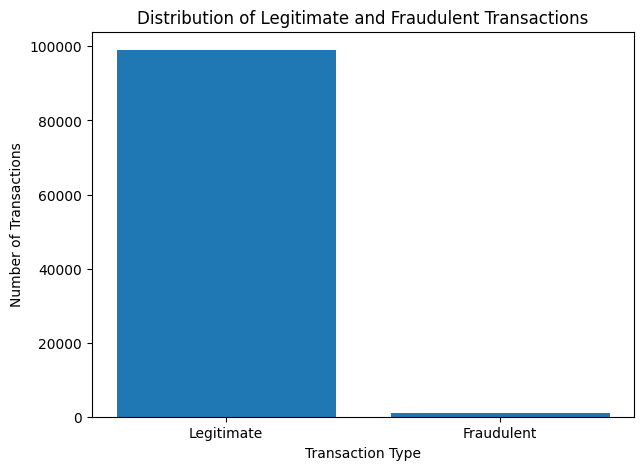

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Legitimate", "Fraudulent"],
    fraud_counts.values
)

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

plt.show()

# 6. Exploratory Data Analysis

Exploratory data analysis is performed to understand relationships between
the transaction variables and fraudulent activity.

Transaction amount is investigated because unusually high or unusual
transaction values may provide predictive information for fraud detection.

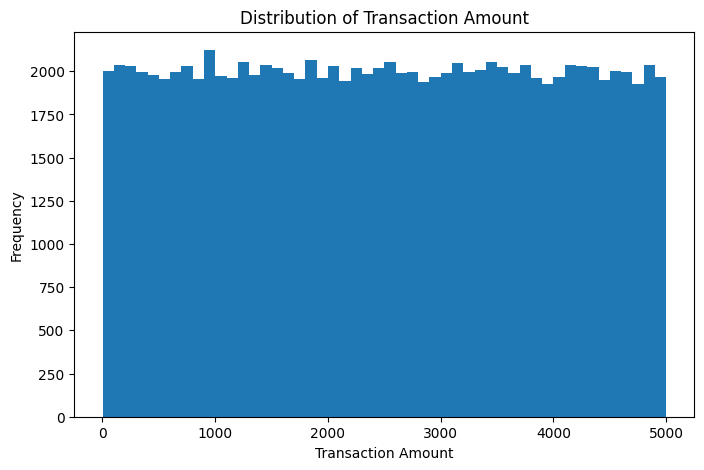

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(df["Amount"], bins=50)

plt.title("Distribution of Transaction Amount")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

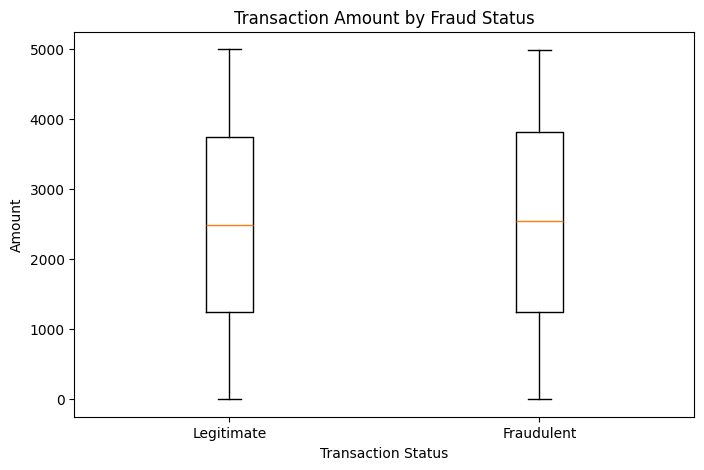

In [ ]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        df[df["IsFraud"] == 0]["Amount"],
        df[df["IsFraud"] == 1]["Amount"]
    ],
    labels=["Legitimate", "Fraudulent"]
)

plt.title("Transaction Amount by Fraud Status")
plt.xlabel("Transaction Status")
plt.ylabel("Amount")

plt.show()

In [ ]:
fraud_by_type = (
    df.groupby("TransactionType")["IsFraud"]
    .mean()
    .sort_values(ascending=False)
)

print("Fraud rate by transaction type:")

display(
    (fraud_by_type * 100)
    .round(2)
    .to_frame("Fraud Rate (%)")
)

Fraud rate by transaction type:


,Fraud Rate (%)
TransactionType,
refund,1.01
purchase,0.99


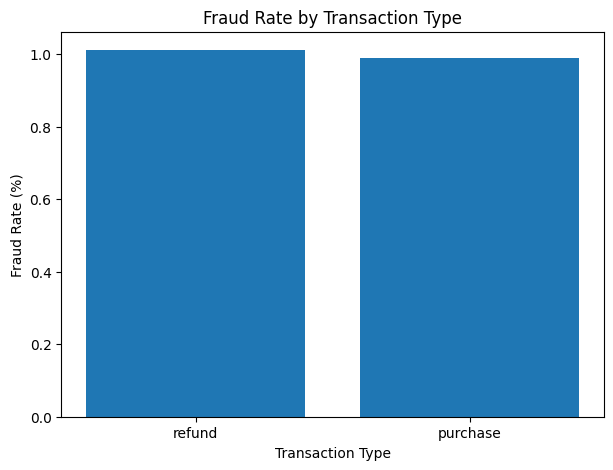

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    fraud_by_type.index,
    fraud_by_type.values * 100
)

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")

plt.show()

In [ ]:
fraud_by_location = (
    df.groupby("Location")["IsFraud"]
    .mean()
    .sort_values(ascending=False)
)

display(
    (fraud_by_location * 100)
    .round(2)
    .to_frame("Fraud Rate (%)")
)

,Fraud Rate (%)
Location,
New York,1.16
San Diego,1.14
Houston,1.05
Phoenix,0.99
San Antonio,0.98
Dallas,0.98
Los Angeles,0.96
Chicago,0.93
Philadelphia,0.91


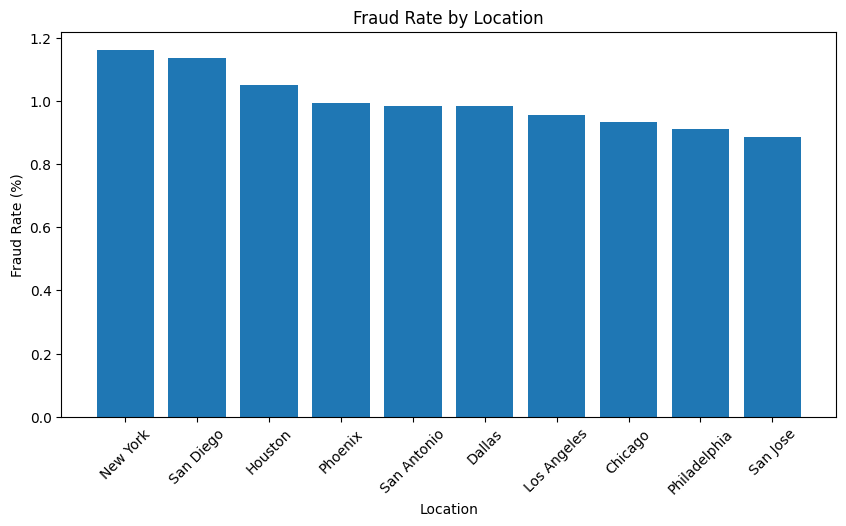

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    fraud_by_location.index,
    fraud_by_location.values * 100
)

plt.title("Fraud Rate by Location")
plt.xlabel("Location")
plt.ylabel("Fraud Rate (%)")

plt.xticks(rotation=45)

plt.show()

# 7. Feature Engineering

The `TransactionDate` variable contains both date and time information.

Instead of using the raw timestamp directly, meaningful features are
created from it:

- Year
- Month
- Day
- Day of week
- Hour
- Minute
- Weekend indicator

The `TransactionID` is removed because it is an identifier rather than a
meaningful transaction characteristic.

In [ ]:
data = df.copy()

data["TransactionDate"] = pd.to_datetime(data["TransactionDate"])

data["Year"] = data["TransactionDate"].dt.year
data["Month"] = data["TransactionDate"].dt.month
data["Day"] = data["TransactionDate"].dt.day
data["DayOfWeek"] = data["TransactionDate"].dt.dayofweek
data["Hour"] = data["TransactionDate"].dt.hour
data["Minute"] = data["TransactionDate"].dt.minute

data["IsWeekend"] = (
    data["DayOfWeek"] >= 5
).astype(int)

data = data.drop(
    columns=["TransactionID", "TransactionDate"]
)

display(data.head())

print("New dataset shape:", data.shape)

,Amount,MerchantID,TransactionType,Location,IsFraud,Year,Month,Day,DayOfWeek,Hour,Minute,IsWeekend
0,4189.27,688,refund,San Antonio,0,2024,4,3,2,14,15,0
1,2659.71,109,refund,Dallas,0,2024,3,19,1,13,20,0
2,784.00,394,purchase,New York,0,2024,1,8,0,10,8,0
3,3514.40,944,purchase,Philadelphia,0,2024,4,13,5,23,50,1
4,369.07,475,purchase,Phoenix,0,2024,7,12,4,18,51,0


New dataset shape: (100000, 12)


In [ ]:
X = data.drop(columns=["IsFraud"])
y = data["IsFraud"]

print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())

Features:


,Amount,MerchantID,TransactionType,Location,Year,Month,Day,DayOfWeek,Hour,Minute,IsWeekend
0,4189.27,688,refund,San Antonio,2024,4,3,2,14,15,0
1,2659.71,109,refund,Dallas,2024,3,19,1,13,20,0
2,784.00,394,purchase,New York,2024,1,8,0,10,8,0
3,3514.40,944,purchase,Philadelphia,2024,4,13,5,23,50,1
4,369.07,475,purchase,Phoenix,2024,7,12,4,18,51,0



Target:


,IsFraud
0,0
1,0
2,0
3,0
4,0


# 8. Train-Test Split

The dataset is divided into training and testing sets.

80% of the observations are used for training and 20% are reserved for
testing.

A stratified split is used to maintain a similar proportion of fraudulent
transactions in both datasets because the target variable is highly
imbalanced.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining fraud rate:", y_train.mean())
print("Testing fraud rate:", y_test.mean())

Training data: (80000, 11)
Testing data: (20000, 11)

Training fraud rate: 0.01
Testing fraud rate: 0.01


In [ ]:
numeric_features = [
    "Amount",
    "MerchantID",
    "Year",
    "Month",
    "Day",
    "DayOfWeek",
    "Hour",
    "Minute",
    "IsWeekend"
]

categorical_features = [
    "TransactionType",
    "Location"
]

numeric_pipeline_A = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_A = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_A = ColumnTransformer([
    ("numeric", numeric_pipeline_A, numeric_features),
    ("categorical", categorical_pipeline_A, categorical_features)
])

print("Preprocessing Strategy A created successfully.")

Preprocessing Strategy A created successfully.


In [ ]:
numeric_pipeline_B = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

categorical_pipeline_B = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "encoder",
        OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        )
    )
])

preprocessor_B = ColumnTransformer([
    ("numeric", numeric_pipeline_B, numeric_features),
    ("categorical", categorical_pipeline_B, categorical_features)
])

print("Preprocessing Strategy B created successfully.")

Preprocessing Strategy B created successfully.


In [ ]:
logistic_model = Pipeline([
    ("preprocessing", preprocessor_A),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)

logistic_probabilities = (
    logistic_model.predict_proba(X_test)[:, 1]
)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [ ]:
rf_preprocessor = ColumnTransformer([
    (
        "numeric",
        SimpleImputer(strategy="median"),
        numeric_features
    ),
    (
        "categorical",
        Pipeline([
            (
                "imputer",
                SimpleImputer(strategy="most_frequent")
            ),
            (
                "encoder",
                OneHotEncoder(handle_unknown="ignore")
            )
        ]),
        categorical_features
    )
])

random_forest_model = Pipeline([
    ("preprocessing", rf_preprocessor),
    (
        "model",
        RandomForestClassifier(
            n_estimators=150,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)

rf_probabilities = (
    random_forest_model.predict_proba(X_test)[:, 1]
)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [ ]:
def evaluate_model(name, y_true, predictions, probabilities):

    return {
        "Model": name,
        "Accuracy": accuracy_score(
            y_true, predictions
        ),
        "Precision": precision_score(
            y_true, predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions,
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        ),
        "Average Precision": average_precision_score(
            y_true, probabilities
        )
    }


results = pd.DataFrame([
    evaluate_model(
        "Logistic Regression",
        y_test,
        logistic_predictions,
        logistic_probabilities
    ),

    evaluate_model(
        "Random Forest",
        y_test,
        rf_predictions,
        rf_probabilities
    )
])

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,Logistic Regression,0.537,0.0085,0.39,0.0166,0.4680,0.0093
1,Random Forest,0.990,0.0000,0.00,0.0000,0.5008,0.0111


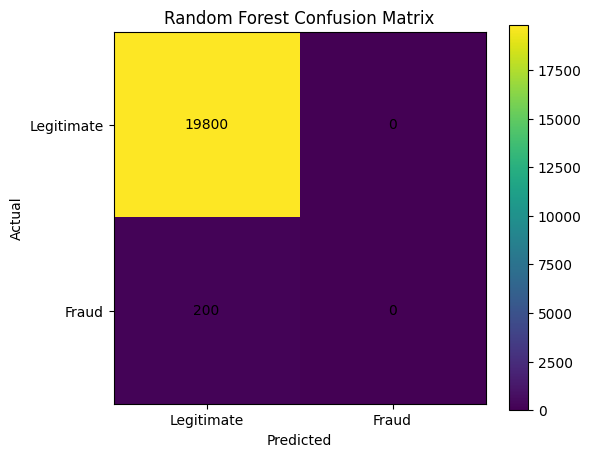

In [ ]:
cm = confusion_matrix(
    y_test,
    rf_predictions
)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.yticks([0, 1], ["Legitimate", "Fraud"])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.show()

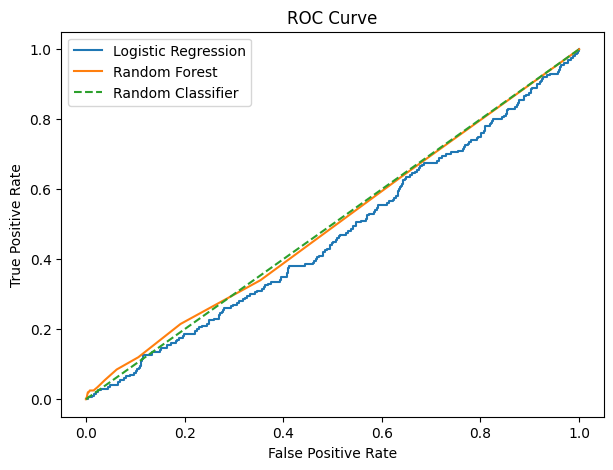

In [ ]:
fpr_log, tpr_log, _ = roc_curve(
    y_test,
    logistic_probabilities
)

fpr_rf, tpr_rf, _ = roc_curve(
    y_test,
    rf_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr_log,
    tpr_log,
    label="Logistic Regression"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label="Random Forest"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

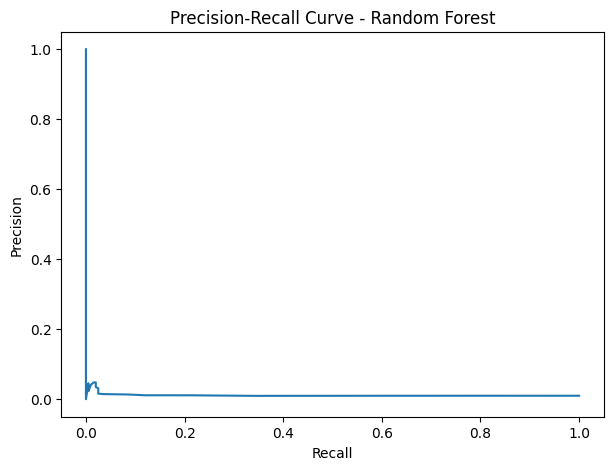

In [ ]:
precision_rf, recall_rf, _ = precision_recall_curve(
    y_test,
    rf_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    recall_rf,
    precision_rf
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision-Recall Curve - Random Forest"
)

plt.show()

In [ ]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [ ]:
logistic_parameters = {
    "model__C": [0.1, 1, 10]
}

logistic_grid = GridSearchCV(
    logistic_model,
    logistic_parameters,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)

print("Best Logistic Regression parameters:")
print(logistic_grid.best_params_)

print(
    "Best cross-validation F1:",
    logistic_grid.best_score_
)

Best Logistic Regression parameters:
{'model__C': 1}
Best cross-validation F1: 0.01873448347515103


In [ ]:
rf_parameters = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10],
    "model__min_samples_leaf": [1, 3]
}

rf_grid = GridSearchCV(
    random_forest_model,
    rf_parameters,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_grid.best_params_)

print(
    "Best cross-validation F1:",
    rf_grid.best_score_
)

Best Random Forest parameters:
{'model__max_depth': 10, 'model__min_samples_leaf': 3, 'model__n_estimators': 100}
Best cross-validation F1: 0.007631345221015235


In [ ]:
best_logistic = logistic_grid.best_estimator_
best_rf = rf_grid.best_estimator_

best_logistic_pred = best_logistic.predict(X_test)
best_logistic_prob = best_logistic.predict_proba(X_test)[:, 1]

best_rf_pred = best_rf.predict(X_test)
best_rf_prob = best_rf.predict_proba(X_test)[:, 1]

final_results = pd.DataFrame([
    evaluate_model(
        "Tuned Logistic Regression",
        y_test,
        best_logistic_pred,
        best_logistic_prob
    ),

    evaluate_model(
        "Tuned Random Forest",
        y_test,
        best_rf_pred,
        best_rf_prob
    )
])

display(final_results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,Tuned Logistic Regression,0.5370,0.0085,0.39,0.0166,0.4680,0.0093
1,Tuned Random Forest,0.9812,0.0111,0.01,0.0105,0.5109,0.0106


# 9. Discussion

The machine learning models were evaluated using accuracy, precision, recall,
F1-score, ROC-AUC and Average Precision.

Accuracy was not considered sufficient as the only evaluation measure because
the dataset contains a substantially larger number of legitimate transactions
than fraudulent transactions.

Precision indicates the proportion of transactions identified as fraudulent
that were actually fraudulent. Recall indicates the proportion of actual
fraudulent transactions successfully detected by the model.

F1-score provides a balance between precision and recall and was therefore
used as the main metric during hyperparameter tuning.

The performance of Logistic Regression and Random Forest was compared to
identify the more suitable model for this fraud detection problem.

The final model selection should consider the balance between detecting
fraudulent transactions and avoiding excessive false alarms.

# 10. Conclusion

This project developed a machine learning approach for detecting fraudulent
credit card transactions.

The project included data exploration, data quality assessment, feature
engineering, two preprocessing strategies, Logistic Regression and Random
Forest classification, machine learning pipelines and hyperparameter tuning.

The results demonstrate the importance of using suitable evaluation metrics
for an imbalanced fraud detection problem. Accuracy alone can provide a
misleading result, while precision, recall, F1-score, ROC-AUC and Average
Precision provide a more comprehensive assessment.

The final model should be selected according to its ability to detect
fraudulent transactions while maintaining an acceptable number of false
positive predictions.

Further work could include additional behavioural transaction features,
time-based validation and testing the models on a larger and more diverse
real-world banking dataset.

# 11. References

1. Scikit-learn. Machine Learning in Python.
   https://scikit-learn.org/

2. Scikit-learn. Logistic Regression.
   https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

3. Scikit-learn. Random Forest Classifier.
   https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

4. Scikit-learn. GridSearchCV.
   https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

5. Scikit-learn. Model Evaluation.
   https://scikit-learn.org/stable/modules/model_evaluation.html

6. Credit Card Fraud Dataset.
   Dataset supplied for this machine learning project.